In [ ]:
!pip install legacy_cgi
!pip install opendatasets

In [ ]:
import opendatasets as od
import os


In [ ]:
data = od.download("https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset")

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: shrutisharma45672
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset


100%|██████████| 157M/157M [00:01<00:00, 149MB/s]


In [ ]:
training_dataset_path = "/content/brain-tumor-mri-dataset/Training"
testing_dataset_path = "/content/brain-tumor-mri-dataset/Testing"

### 1. Load and Preprocess the Dataset
We will use `keras.utils.image_dataset_from_directory` to load our images, resize them to `150x150`, and split the training folder into an 80/20 train/validation split.

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# Configure parameters
BATCH_SIZE = 32
IMG_SIZE = (150, 150)

# Load training dataset
train_ds = tf.keras.utils.image_dataset_from_directory(
    training_dataset_path,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Load validation dataset
val_ds = tf.keras.utils.image_dataset_from_directory(
    training_dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Load testing dataset
test_ds = tf.keras.utils.image_dataset_from_directory(
    testing_dataset_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
print("Class names found:", class_names)

Found 5600 files belonging to 4 classes.
Using 4480 files for training.
Found 5600 files belonging to 4 classes.
Using 1120 files for validation.
Found 1600 files belonging to 4 classes.
Class names found: ['glioma', 'meningioma', 'notumor', 'pituitary']


### 2. Build the CNN Model
We will create a Sequential CNN architecture. It includes scaling/normalization, three convolutional blocks followed by max-pooling, a flattening layer, a dense layer with dropout for regularization, and a final classification layer.

In [ ]:
num_classes = len(class_names)

model = models.Sequential([
    # Rescale pixel values from [0, 255] to [0, 1]
    layers.Rescaling(1./255, input_shape=(150, 150, 3)),

    # First Convolutional Block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Second Convolutional Block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Third Convolutional Block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Flatten and Fully Connected Layers
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5), # Helps prevent overfitting
    layers.Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,868 (18.42 MB)

 Trainable params: 4,828,868 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

### 3. Train the Model
Let's run the model training for 10 epochs to see how it performs.

In [ ]:
EPOCHS = 10
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 55ms/step - accuracy: 0.6507 - loss: 0.8742 - val_accuracy: 0.8455 - val_loss: 0.4653
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - accuracy: 0.8080 - loss: 0.5103 - val_accuracy: 0.7902 - val_loss: 0.4729
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - accuracy: 0.8576 - loss: 0.3914 - val_accuracy: 0.9134 - val_loss: 0.2741
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 6s 43ms/step - accuracy: 0.8967 - loss: 0.2847 - val_accuracy: 0.9152 - val_loss: 0.2334
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 6s 42ms/step - accuracy: 0.9116 - loss: 0.2282 - val_accuracy: 0.9152 - val_loss: 0.2279
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 11s 49ms/step - accuracy: 0.9353 - loss: 0.1798 - val_accuracy: 0.9205 - val_loss: 0.2099
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 6s 39ms/step - accuracy: 0.9571 - loss: 0.1215 - val_accuracy: 0.9179 - val_loss: 0.2689
Epoch 8/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 7s 49ms/step - accuracy: 0.9629 - loss: 0.0970 - val_ac

### 4. Plot Loss and Accuracy Curves
Let's plot the training and validation history to see how well our model learned and check for overfitting.

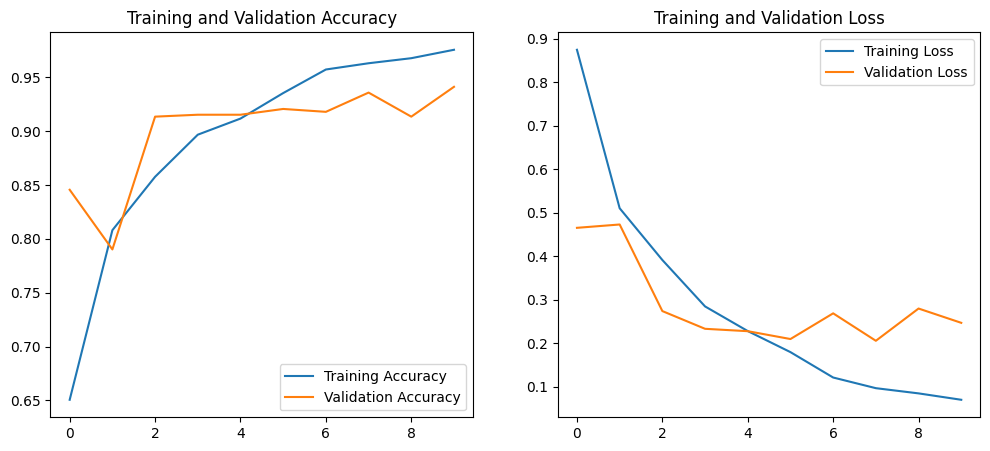

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(EPOCHS)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

### 5. Evaluate the Model on the Test Dataset
Now, we evaluate the finalized model parameters against our completely unseen test set.

In [ ]:
test_loss, test_accuracy = model.evaluate(test_ds)
print(f"Test Accuracy: {test_accuracy*100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.8838 - loss: 1.0600
Test Accuracy: 88.38%
Test Loss: 1.0600


### 6. Predict on a Single Test Image
Let's grab a batch of images from the test set, show one of them along with its ground truth label, and see what our trained model predicts.

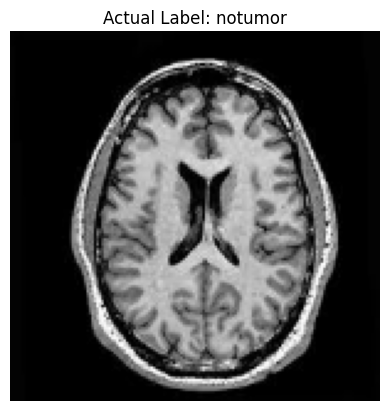

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Predicted Class: notumor (100.00% confidence)


In [ ]:
import numpy as np

# Retrieve a batch of images from the test set
image_batch, label_batch = next(iter(test_ds))
first_image = image_batch[0]
first_label = label_batch[0]

# Display the image
plt.imshow(first_image.numpy().astype("uint8"))
plt.title(f"Actual Label: {class_names[first_label]}")
plt.axis("off")
plt.show()

# Add batch dimension and get model prediction
img_array = tf.expand_dims(first_image, 0)
predictions = model.predict(img_array)
score = tf.nn.softmax(predictions[0])

predicted_class = class_names[np.argmax(predictions)]
confidence = 100 * np.max(predictions)

print(f"Predicted Class: {predicted_class} ({confidence:.2f}% confidence)")

### 7. Evaluate Performance using a Confusion Matrix
We will extract all the true labels and predicted labels from the `test_ds` batch by batch, and use `scikit-learn` and `seaborn` to display a beautiful confusion matrix.

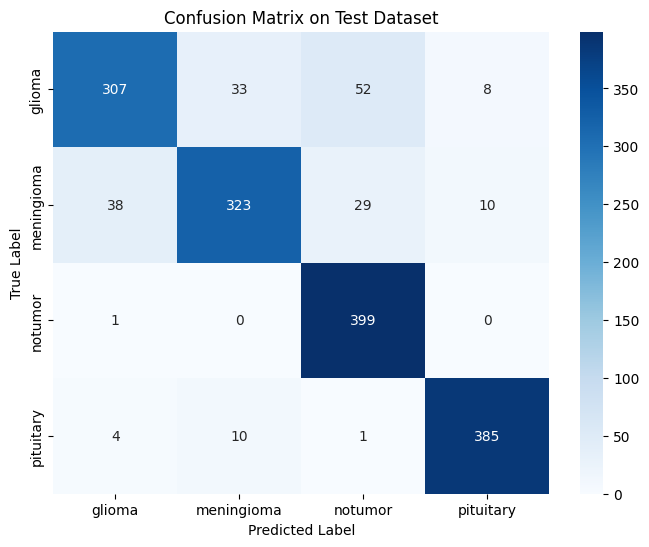

              precision    recall  f1-score   support

      glioma       0.88      0.77      0.82       400
  meningioma       0.88      0.81      0.84       400
     notumor       0.83      1.00      0.91       400
   pituitary       0.96      0.96      0.96       400

    accuracy                           0.88      1600
   macro avg       0.89      0.88      0.88      1600
weighted avg       0.89      0.88      0.88      1600



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

y_true = []
y_pred = []

# Loop through the test dataset batches to collect true and predicted labels
for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

# Calculate the confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot the Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix on Test Dataset')
plt.show()

# Print the Classification Report
print(classification_report(y_true, y_pred, target_names=class_names))

### 8. Save the Trained Model
Save the model structure and its trained weights to a standard keras archive file.

In [ ]:
model_save_path = '/content/brain_tumor_cnn_model.keras'
model.save(model_save_path)
print(f"Model successfully saved to: {model_save_path}")

Model successfully saved to: /content/brain_tumor_cnn_model.keras
